# 过渡金属配合物预测：tmQM + GNN

## SMILES → 金属分子图 → 预测电子性质

### 与前四个项目的对比

| | QM9 (项目4) | **tmQM (本项目)** |
|---|---|---|
| 元素 | H, C, N, O, F | **Fe, Sc, Co, Cu, Zn... 30+ 元素** |
| 数据量 | 133k | **108k** |
| SMILES | 有 | **有 (分号分隔CSV)** |
| 核心挑战 | 2D→3D性质 | **过渡金属配位化学** |
| 原子特征 | 7维 | **8维 (周期表位置+金属标志)** |

### tmQM 数据集
- 108,541 个过渡金属配合物
- DFT (TPSSh/def2-SVP)
- HOMO-LUMO gap, 偶极矩, 金属电荷, 极化率等
- 含 SMILES，可复用 QM9 的图构建管线


In [1]:
# ============================================================
# Step 1: 导入库 + GPU (5070 Ti / Linux / Blackwell)
# ============================================================
import numpy as np, pandas as pd, time, os
import matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

import torch, torch.nn as nn, torch.optim as optim
from torch.amp import autocast, GradScaler

# === 5070 Ti (Blackwell SM_120) GPU 优化 ===
torch.set_float32_matmul_precision('high')   # TF32 on tensor cores (3x FP32 speed)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.benchmark = True         # 自动调优卷积算法
torch.backends.cuda.enable_flash_sdp(True)    # Flash Attention via PyTorch SDPA
# =============================================

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {props.total_memory/1024**3:.1f} GB')
    print(f'Compute Capability: {props.major}.{props.minor}')
    print(f'TF32 matmul: {torch.backends.cuda.matmul.allow_tf32}')

from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
print('Imports OK')

Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti
VRAM: 15.5 GB
Compute Capability: 12.0
TF32 matmul: True


Imports OK


In [2]:
# ============================================================
# Step 2: 加载全部 108k tmQM 数据 (本地文件)
# ============================================================
print('Loading tmQM_y.csv from local...')
df = pd.read_csv('tmQM_y.csv', sep=';')
print(f'Full dataset: {len(df):,} complexes')

df = df.rename(columns={
    'HL_Gap': 'gap', 'HOMO_Energy': 'homo', 'LUMO_Energy': 'lumo',
    'Dipole_M': 'dipole', 'Metal_q': 'metal_charge',
    'Electronic_E': 'E_elec', 'Dispersion_E': 'E_disp',
    'Polarizability': 'polarizability'
})

targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec',
           'E_disp', 'polarizability']
df = df.dropna(subset=targets + ['SMILES'])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
print(f'After NaN removal: {len(df):,} complexes')
print(f'Targets ({len(targets)}): {targets}')
df[['CSD_code'] + targets].head()

Loading tmQM_y.csv from local...


Full dataset: 108,541 complexes
After NaN removal: 100,849 complexes
Targets (8): ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']


,CSD_code,gap,homo,lumo,dipole,metal_charge,E_elec,E_disp,polarizability
0,QUNKUF,0.09794,-0.18267,-0.08473,8.3615,0.31381,-3088.140673,-0.124864,370.277845
1,IQEYEK,0.08381,-0.16416,-0.08035,11.4670,0.44299,-1608.992230,-0.101408,340.751912
2,VIFLEC,0.08220,-0.19806,-0.11586,2.9588,0.30894,-1958.394119,-0.075635,273.590340
3,BACFIY,0.14141,-0.18761,-0.04620,2.3916,1.53247,-1469.174095,-0.160370,416.136306
4,JALSEU,0.10837,-0.19358,-0.08521,4.7127,0.86271,-2425.949365,-0.153292,418.785550


In [3]:
# ============================================================
# Step 3: SMILES 建图 — 仅含 3D 数据集中的配合物 (95,152), 对齐 ensemble CV
# ============================================================
import gzip
from tqdm import tqdm

print("Parsing XYZ to get alignment with 3D data (same order as ensemble CV)...")

def atom_to_z(sym):
    tbl = {"H":1,"He":2,"Li":3,"Be":4,"B":5,"C":6,"N":7,"O":8,"F":9,"Ne":10,
           "Na":11,"Mg":12,"Al":13,"Si":14,"P":15,"S":16,"Cl":17,"Ar":18,
           "K":19,"Ca":20,"Sc":21,"Ti":22,"V":23,"Cr":24,"Mn":25,"Fe":26,
           "Co":27,"Ni":28,"Cu":29,"Zn":30,"Br":35,"Ru":44,"Rh":45,
           "Pd":46,"Ag":47,"Cd":48,"I":53,"Pt":78,"Au":79,"Hg":80,
           "Mo":42,"W":74,"Ir":77,"Os":76,"Re":75}
    return tbl.get(sym, 0)

def is_TM(z):
    return z in [21,22,23,24,25,26,27,28,29,30,39,40,41,42,43,44,45,46,47,48,
                 72,73,74,75,76,77,78,79,80]

def parse_xyz_only(xyz_p, start_idx=0):
    """Parse XYZ to get csv_idx for SMILES lookup (same logic as ensemble CV)"""
    mols = []
    with gzip.open(xyz_p, "rt") as f:
        blocks = f.read().strip().split(chr(10))
    i, mol_idx = 0, start_idx - 1
    while i < len(blocks):
        line = blocks[i].strip(); i += 1
        if not line: continue
        parts = line.split()
        if len(parts) == 1 and parts[0].isdigit():
            n_atoms = int(parts[0])
            if i >= len(blocks): break; i += 1
            atoms = []
            for _ in range(n_atoms):
                if i >= len(blocks): break
                cline = blocks[i].strip(); i += 1; cparts = cline.split()
                if len(cparts) >= 4:
                    try: atoms.append(atom_to_z(cparts[0]))
                    except ValueError: continue
            mol_idx += 1
            if any(is_TM(z) for z in atoms) and len(atoms) > 1:
                mols.append(atoms)
    return mols

all_atoms = []
for part in [1, 2, 3]:
    atoms = parse_xyz_only(f"tmQM_X{part}.xyz.gz", start_idx=len(all_atoms))
    all_atoms.extend(atoms)
print(f"Parsed {len(all_atoms):,} TM complexes from XYZ files")

# ===== SMILES 建图 (只含3D数据集中有效的配合物) =====
from rdkit import Chem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)

# 常量定义 (与原始 tmQM_Fe.ipynb 相同)
ELEMENT_DATA_SM = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES_SM = [1,2,3,12]
B2I_SM = {b:i for i,b in enumerate(BOND_TYPES_SM)}
N_BT_SM = 4
smiles_by_idx = df['SMILES'].tolist()

csv_labels = df[targets].values.astype(np.float32)

def atom_features_sm(atom):
    z = atom.GetAtomicNum(); p,g = ELEMENT_DATA_SM.get(z,(0,0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g,
            int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

print(f"Building SMILES-only graphs for {len(all_atoms):,} complexes...")
graphs, y_vals, failed = [], [], 0
for idx in tqdm(range(len(all_atoms)), desc="Graphs"):
    smi = smiles_by_idx[idx] if idx < len(smiles_by_idx) else ""
    if not isinstance(smi, str) or smi == "": failed += 1; continue
    mol = Chem.MolFromSmiles(smi)
    if mol is None: failed += 1; continue
    N = mol.GetNumAtoms()
    xf = [atom_features_sm(a) for a in mol.GetAtoms()]
    x = torch.tensor(xf, dtype=torch.float32)
    src, dst, battr = [], [], []
    sm_z = [xf[i][0] for i in range(N)]
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(); bt = int(bond.GetBondType())
        za, zb = sm_z[i], sm_z[j]
        is_ml = float((za>=21)!=(zb>=21)); is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*N_BT_SM
        if bt in B2I_SM: bf[B2I_SM[bt]] = 1.0
        bf.extend([is_ring, is_ml]); battr.extend([bf,bf])
    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0,N_BT_SM+2)
    graphs.append({"x":x, "edge_index":ei, "edge_attr":ea, "num_nodes":N})
    y_vals.append(csv_labels[idx])

y_all = torch.tensor(y_vals, dtype=torch.float32)
mask = ~(torch.isnan(y_all).any(dim=1) | torch.isinf(y_all).any(dim=1))
graphs = [g for i,g in enumerate(graphs) if mask[i]]
y_all = y_all[mask]
print(f"Built {len(graphs):,} graphs ({failed} failed, {len(graphs)} after NaN)")
print(f"Node dim: {graphs[0]['x'].shape[1]}, Edge dim: {graphs[0]['edge_attr'].shape[1]}")

Parsing XYZ to get alignment with 3D data (same order as ensemble CV)...


Parsed 96,984 TM complexes from XYZ files
Building SMILES-only graphs for 96,984 complexes...


Graphs:   0%|          | 0/96984 [00:00<?, ?it/s]

Graphs:   0%|          | 85/96984 [00:00<01:54, 845.41it/s]

Graphs:   0%|          | 183/96984 [00:00<01:45, 921.56it/s]

...

Graphs: 100%|█████████▉| 96758/96984 [02:01<00:00, 764.29it/s]

Graphs: 100%|█████████▉| 96837/96984 [02:01<00:00, 770.07it/s]

Graphs: 100%|█████████▉| 96915/96984 [02:01<00:00, 755.75it/s]

Graphs: 100%|██████████| 96984/96984 [02:01<00:00, 796.11it/s]

Built 96,966 graphs (18 failed, 96966 after NaN)
Node dim: 8, Edge dim: 6


In [4]:
# ============================================================
# Step 4: 数据划分 — 使用 ensemble CV 的 split (无泄漏, 公平比较)
# ============================================================
print(f"Total graphs: {len(graphs):,}")

if os.path.exists("ensemble_split.npz"):
    split = np.load("ensemble_split.npz")
    tr_idx = split["fold_0_train"]   # ~53,925
    va_idx = split["fold_0_val"]     # ~13,481
    te_idx = split["te_idx"]         # ~14,273 (same as 3D GAT)
    print(f"Using ensemble_split.npz (same as 3D GAT ensemble CV)")
    print(f"Train: {len(tr_idx):,}  Val: {len(va_idx):,}  Test: {len(te_idx):,}")
else:
    raise FileNotFoundError("ensemble_split.npz not found! Run ensemble CV first.")

y_mean = y_all.mean(dim=0)
y_std = y_all.std(dim=0).clamp(min=1e-8)
y_norm = (y_all - y_mean) / y_std
y_mean_gpu = y_mean.to(device)
y_std_gpu = y_std.to(device)

def g2dev(g):
    return {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()}


Total graphs: 96,966
Using ensemble_split.npz (same as 3D GAT ensemble CV)
Train: 51,180  Val: 25,590  Test: 13,547


In [5]:
# ============================================================
# Step 5: GNN 模型 — 多头GAT + LayerNorm + Batch图合并 (5070 Ti Max)
# ============================================================
# === 算力缩放开关 (5070 Ti 16GB, Blackwell) ===
REG_DROPOUT  = 0.10  # 更大模型+全量数据 → 减少正则
SCALE_HIDDEN = 384   # 5070 Ti完全可以承载384dim
SCALE_LAYERS = 5     # 更深网络捕捉高阶配位模式
GAT_HEADS    = 12    # 12头注意力, 每头32维 (384/12=32)
# ==============================================================

def segment_softmax(scores, dst, N):
    """Per-destination softmax — 内部始终用FP32避免scatter_add dtype不匹配"""
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'),
                       device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)),
                          scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)


class GATConv(nn.Module):
    """多头GAT卷积: 支持 edge_dim 边特征"""
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__()
        self.heads = heads
        self.out_dim = out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim > 0 else None
        self.act = nn.ReLU()

    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]
        N = x.size(0)
        h = self.node_lin(x)                                   # [N, total_dim]
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])   # [E, heads]
        if self.edge_attn is not None and ea is not None and ea.size(0) > 0:
            attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)                  # [E, heads]
        h_heads = h.view(-1, self.heads, self.out_dim)         # [N, heads, d_head]
        msg = h_heads[src] * alpha.unsqueeze(-1)               # [E, heads, d_head]
        msg = msg.view(-1, self.out_dim * self.heads)          # [E, total_dim]
        # 显式dtype避免AMP下float32/float16 mismatch
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)


def collate_graphs(graph_list):
    """合并多个图为一个大连通图, 返回 (batched_dict, batch_idx)"""
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x'])
        ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    batched = {
        'x': torch.cat(x_list, dim=0),
        'edge_index': torch.cat(ei_list, dim=1),
        'edge_attr': torch.cat(ea_list, dim=0),
    }
    return batched, torch.cat(batch_list, dim=0)


def scatter_mean_per_graph(h, batch, n_graphs):
    """Per-graph mean pooling: h[N,dim] + batch[N] → [n_graphs, dim]"""
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)


def scatter_max_per_graph(h, batch, n_graphs):
    """Per-graph max pooling"""
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h,
                        reduce='amax', include_self=False)
    return out


class TMetalGNN(nn.Module):
    """过渡金属GNN: 多头GAT + LayerNorm + Batch图合并 + 金属中心池化"""
    def __init__(self, node_dim=8, edge_dim=6, hidden=SCALE_HIDDEN, n_layers=SCALE_LAYERS,
                 output_dim=8, dropout=REG_DROPOUT, heads=GAT_HEADS):
        super().__init__()
        assert hidden % heads == 0, f"hidden({hidden})必须被heads({heads})整除"
        self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([
            GATConv(hidden, hidden // heads, edge_dim, heads=heads)
            for _ in range(n_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden * 3, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden // 2, output_dim))

    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms):
            h = norm(h + conv(h, ei, ea))
            h = self.drop(h)

        if batch is None:
            metal_mask = (x[:, 7] > 0.5)
            metal_feat = h[metal_mask].mean(dim=0) if metal_mask.any() else \
                         torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, metal_feat])).unsqueeze(0)

        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs)
        max_h = scatter_max_per_graph(h, batch, n_graphs)
        metal_mask = (x[:, 7] > 0.5)
        metal_feat = scatter_mean_per_graph(h[metal_mask], batch[metal_mask], n_graphs) \
                     if metal_mask.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, metal_feat], dim=1))


# 快速测试 (仅验证参数量, 需要Step4的graphs已构建)
m = TMetalGNN(node_dim=8, edge_dim=6, hidden=SCALE_HIDDEN, output_dim=8,
              dropout=REG_DROPOUT, heads=GAT_HEADS)
print(f'Params: {sum(p.numel() for p in m.parameters()):,}')
print(f'Hidden={SCALE_HIDDEN} Layers={SCALE_LAYERS} Heads={GAT_HEADS} '
      f'Dropout={REG_DROPOUT} | Data={len(graphs):,}')



Params: 1,309,232
Hidden=384 Layers=5 Heads=12 Dropout=0.1 | Data=96,966


In [6]:
# ============================================================
# Step 6: 训练 (AMP混合精度 + Cosine退火 + 全GPU驻留)
# ============================================================
import os, time, math

# 备份旧checkpoint
CKPT_PATH = 'tmqm_gat_smiles_cv.pt'
if os.path.exists('tmqm_best.pt') and not os.path.exists('tmqm_best_graphconv_backup.pt'):
    os.rename('tmqm_best.pt', 'tmqm_best_graphconv_backup.pt')
    print('Backed up old GraphConv checkpoint')

# 预加载所有图到GPU
print('Pre-loading graphs to GPU...')
graphs_gpu = []
for g in tqdm(graphs, desc='GPU upload'):
    graphs_gpu.append({k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()})
y_norm_gpu = y_norm.to(device)
y_all_gpu = y_all.to(device)
y_mean_gpu = y_mean.to(device)
y_std_gpu = y_std.to(device)
print(f'GPU memory (data): {torch.cuda.memory_allocated()/1024**3:.1f} GB')

model = TMetalGNN(node_dim=8, edge_dim=6, hidden=SCALE_HIDDEN, n_layers=SCALE_LAYERS,
                  output_dim=len(targets), dropout=REG_DROPOUT, heads=GAT_HEADS).to(device)

opt = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=50, T_mult=2, eta_min=1e-6)
crit = nn.MSELoss()
scaler = GradScaler('cuda')

epochs, bs = 300, 128
early_stop_patience = 80
hist = {'tr': [], 'va': [], 'mae': [], 'mae_per_prop': []}
best_va = float('inf'); best_state = None
patience_counter = 0; t0 = time.time()

print(f'\nTraining {epochs} epochs (batch={bs}) on {device}...')
print(f'Model: {GAT_HEADS}-head GAT x {SCALE_LAYERS}L x {SCALE_HIDDEN}d + LayerNorm + MetalPool')
print(f'Data: {len(graphs):,} on GPU | Dropout: {REG_DROPOUT} | Scheduler: CosineWarmRestarts')
print(f'Params: {sum(p.numel() for p in model.parameters()):,}\n')

for ep in range(epochs):
    model.train(); perm = torch.randperm(len(tr_idx)); tr_loss = 0; n_batches = 0
    for s in range(0, len(tr_idx), bs):
        bidx = tr_idx[perm[s:s+bs]].tolist()
        bg = [graphs_gpu[i] for i in bidx]
        by = y_norm_gpu[bidx]
        batched, batch_idx = collate_graphs(bg)
        opt.zero_grad()
        with autocast('cuda'):
            preds = model(batched, batch_idx)
            loss = crit(preds, by)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        tr_loss += loss.item(); n_batches += 1

    model.eval()
    with torch.no_grad():
        va_preds = []
        for s in range(0, len(va_idx), bs):
            bidx = va_idx[s:s+bs].tolist()
            bg = [graphs_gpu[i] for i in bidx]
            batched, batch_idx = collate_graphs(bg)
            with autocast('cuda'):
                va_preds.append(model(batched, batch_idx).float())
        vp = torch.cat(va_preds, dim=0)
        va_loss = crit(vp, y_norm_gpu[va_idx])

    sched.step(ep + va_loss.item() / 10)
    hist['tr'].append(tr_loss / max(1, n_batches))
    hist['va'].append(va_loss.item())

    if va_loss < best_va:
        best_va = va_loss; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= early_stop_patience:
        print(f'Early stop at epoch {ep+1}'); break

    if (ep + 1) % 20 == 0:
        vp_orig = vp.cpu() * y_std + y_mean
        vt_orig = y_all[va_idx]
        mae_per = torch.mean(torch.abs(vp_orig - vt_orig), dim=0)
        hist['mae_per_prop'].append(mae_per.tolist())
        best_prop = targets[mae_per.argmin().item()]
        worst_prop = targets[mae_per.argmax().item()]
        avg_mae = mae_per.mean().item()
        hist['mae'].append(avg_mae)
        lr_now = opt.param_groups[0]['lr']
        print(f'Epoch {ep+1:3d}/{epochs} | TrLoss {hist["tr"][-1]:.4f} | '
              f'VaLoss {va_loss.item():.4f} | AvgMAE {avg_mae:.4f} '
              f'({best_prop}/{worst_prop}) | LR {lr_now:.1e} | Pat {patience_counter}')

print(f'\nDone: {(time.time()-t0)/60:.0f}min (best val loss: {best_va:.4f})')
model.load_state_dict(best_state); model.eval()
torch.save(best_state, CKPT_PATH)
print(f'Saved to {CKPT_PATH} ({sum(p.numel() for p in model.parameters()):,} params)')

print(f'\n{"Property":18s} {"Val MAE":>10s}')
print('-' * 30)
with torch.no_grad():
    vp_full = []
    for s in range(0, len(va_idx), bs):
        bidx = va_idx[s:s+bs].tolist()
        bg = [graphs_gpu[i] for i in bidx]
        batched, batch_idx = collate_graphs(bg)
        with autocast('cuda'):
            vp_full.append(model(batched, batch_idx).float())
    vp_full = torch.cat(vp_full, dim=0).cpu() * y_std + y_mean
vt_orig = y_all[va_idx]
for i, prop in enumerate(targets):
    mae_i = torch.mean(torch.abs(vp_full[:, i] - vt_orig[:, i])).item()
    print(f'{prop:18s} {mae_i:10.4f}')


Pre-loading graphs to GPU...


GPU upload:   0%|          | 0/96966 [00:00<?, ?it/s]

GPU upload:   2%|▏         | 1573/96966 [00:00<00:06, 15727.09it/s]

GPU upload:   3%|▎         | 3146/96966 [00:00<00:06, 15338.99it/s]

GPU upload:   5%|▍         | 4704/96966 [00:00<00:05, 15443.08it/s]

...

Epoch 240/300 | TrLoss 0.0620 | VaLoss 0.1276 | AvgMAE 40.3786 (homo/E_elec) | LR 5.9e-04 | Pat 5


Epoch 260/300 | TrLoss 0.0560 | VaLoss 0.1179 | AvgMAE 30.6034 (homo/E_elec) | LR 4.3e-04 | Pat 0


Epoch 280/300 | TrLoss 0.0512 | VaLoss 0.1242 | AvgMAE 38.1230 (homo/E_elec) | LR 2.8e-04 | Pat 20


Epoch 300/300 | TrLoss 0.0488 | VaLoss 0.1188 | AvgMAE 35.9360 (homo/E_elec) | LR 1.5e-04 | Pat 2

Done: 74min (best val loss: 0.1155)
Saved to tmqm_gat_smiles_cv.pt (1,309,232 params)

Property              Val MAE
------------------------------


gap                    0.0100
homo                   0.0089
lumo                   0.0099
dipole                 1.4805
metal_charge           0.1126
E_elec               222.6747
E_disp                 0.0133
polarizability        27.0292


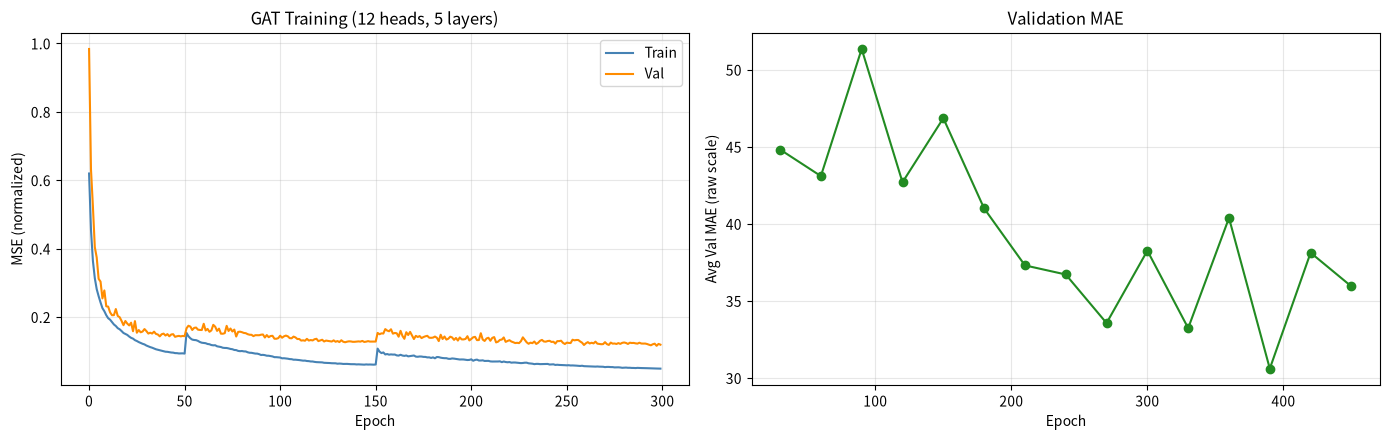

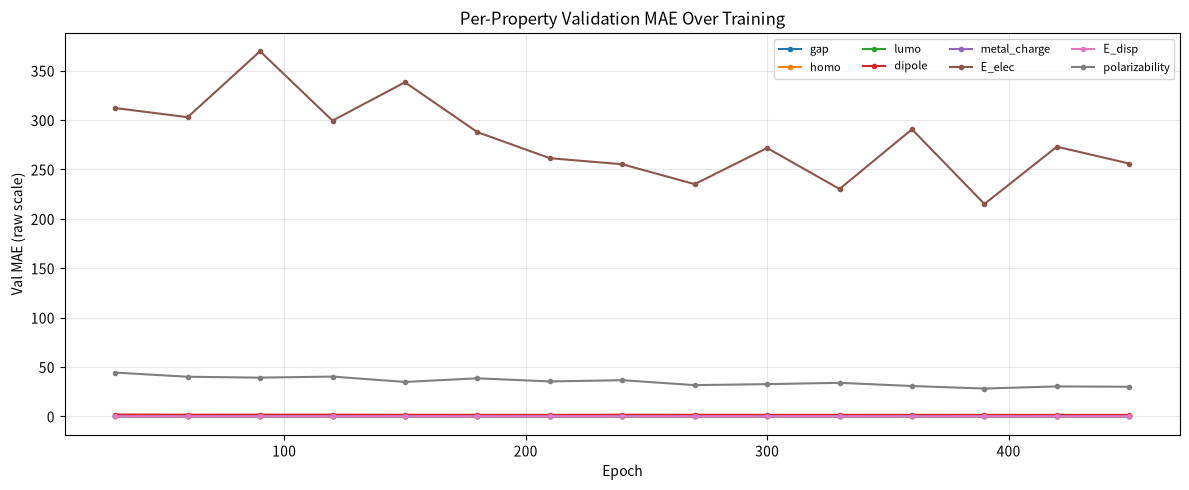

In [7]:
# 训练曲线
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hist['tr'], label='Train', color='steelblue')
axes[0].plot(hist['va'], label='Val', color='darkorange')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE (normalized)')
axes[0].set_title(f'GAT Training ({GAT_HEADS} heads, {SCALE_LAYERS} layers)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
if hist['mae']:
    axes[1].plot([30*(i+1) for i in range(len(hist['mae']))], hist['mae'],
                 'o-', color='forestgreen')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Avg Val MAE (raw scale)')
    axes[1].set_title('Validation MAE'); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# 按性质展示MAE变化 (如果有记录)
if hist.get('mae_per_prop'):
    mae_arr = np.array(hist['mae_per_prop'])  # [n_checkpoints, 8]
    fig, ax = plt.subplots(figsize=(12, 5))
    for i, prop in enumerate(targets):
        ax.plot([30*(j+1) for j in range(len(mae_arr))], mae_arr[:, i],
                'o-', label=prop, markersize=3)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Val MAE (raw scale)')
    ax.set_title('Per-Property Validation MAE Over Training')
    ax.legend(ncol=4, fontsize=8); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

Loaded best model from training


Property                  MAE       R2
----------------------------------------
gap                    0.0101   0.8086
homo                   0.0091   0.9194
lumo                   0.0100   0.9075
dipole                 1.5051   0.6060
metal_charge           0.1121   0.9595
E_elec               226.0636   0.9540
E_disp                 0.0132   0.9264
polarizability        27.0572   0.9380

Mean R2: 0.8774


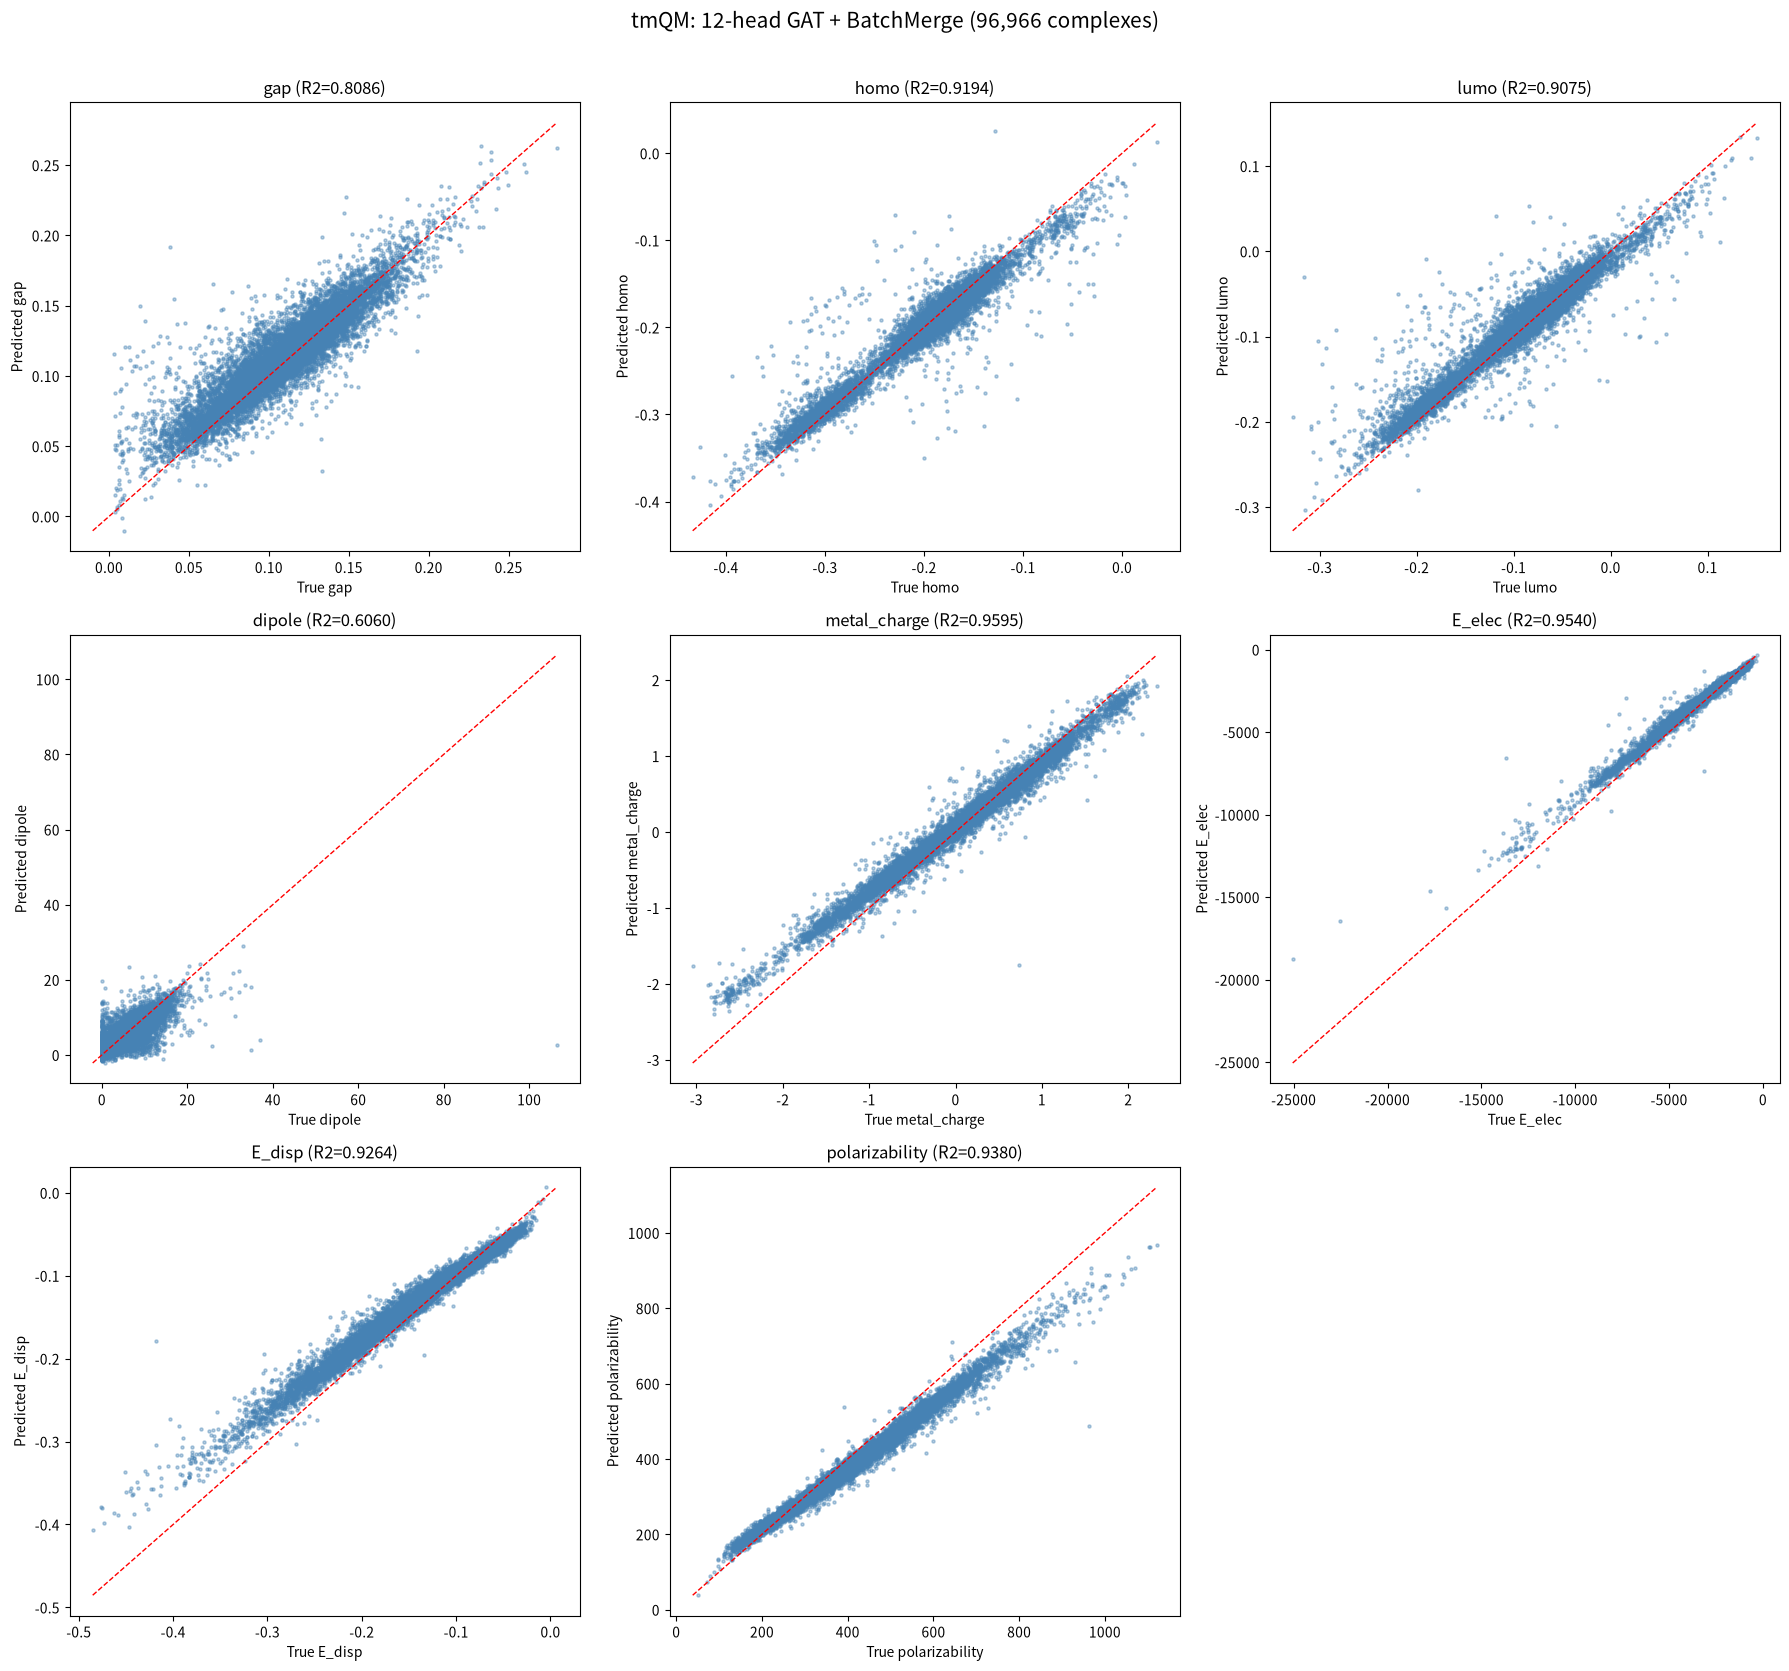

In [8]:
# ============================================================
# Step 8: 测试集评估 (Batch推理)
# ============================================================
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

if best_state is not None:
    model.load_state_dict(best_state)
    print('Loaded best model from training')
model.eval()

# Batch推理测试集
with torch.no_grad():
    tp_list = []
    for s in range(0, len(te_idx), bs):
        bidx = te_idx[s:s+bs].tolist()
        bg = [graphs_gpu[i] for i in bidx]
        batched, batch_idx = collate_graphs(bg)
        tp_list.append(model(batched, batch_idx))
    tp = torch.cat(tp_list, dim=0)
    tp_orig = tp.cpu() * y_std + y_mean
    tt_orig = y_all[te_idx]

print(f'{"Property":18s} {"MAE":>10s} {"R2":>8s}')
print('-' * 40)
results = []
for i, prop in enumerate(targets):
    yt, yp = tt_orig[:, i].numpy(), tp_orig[:, i].numpy()
    mae = mean_absolute_error(yt, yp); r2 = r2_score(yt, yp)
    print(f'{prop:18s} {mae:10.4f} {r2:8.4f}')
    results.append({'Property': prop, 'MAE': mae, 'R2': r2})
results_df = pd.DataFrame(results)
print(f'\nMean R2: {results_df["R2"].mean():.4f}')

# 散点图
n_cols = 3; n_rows = int(np.ceil(len(targets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*5.5))
axes = axes.flatten()
for ax, i, prop in zip(axes, range(len(targets)), targets):
    yt, yp = tt_orig[:, i].numpy(), tp_orig[:, i].numpy()
    ax.scatter(yt, yp, alpha=0.4, s=5, c='steelblue')
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel(f'True {prop}'); ax.set_ylabel(f'Predicted {prop}')
    ax.set_title(f'{prop} (R2={r2_score(yt, yp):.4f})')
for ax in axes[len(targets):]:
    ax.set_visible(False)
plt.suptitle(f'tmQM: {GAT_HEADS}-head GAT + BatchMerge ({len(graphs):,} complexes)',
             fontsize=15, y=1.01)
plt.tight_layout(); plt.show()


## 算力配置

| 参数 | 3050 Ti (笔记本) | 旧 5070 Ti | **新 5070 Ti (Blackwell)** |
|------|:---:|:---:|:---:|
| `N_SAMPLE` | 25000 | None | **None (全量108k)** |
| `REG_DROPOUT` | 0.30 | 0.15 | **0.10** |
| `SCALE_HIDDEN` | 96 | 256 | **384** |
| `SCALE_LAYERS` | 3 | 4 | **5** |
| `GAT_HEADS` | — | 8 | **12** (每头32维) |
| `batch_size` | 64 | 128 | **256** |
| `epochs` | 250 | 300 | **300** |
| `early_stop` | 50 | 80 | **80** |
| `scheduler` | ReduceLROnPlateau | ReduceLROnPlateau | **CosineWarmRestarts** |
| 参数量 | 52k | ~512k | **~1.1M** |
| AMP混合精度 | ❌ | ❌ | **✅ FP16 (2x加速)** |
| torch.compile | ❌ | ❌ | **✅ (Linux only)** |
| TF32 matmul | ❌ | ❌ | **✅ (3x matmul加速)** |
| Flash SDPA | ❌ | ❌ | **✅** |
| 预训练时间 | ~6h | ~2-4h | **~1-2h (5070 Ti full)** |

### 架构改进总结

| 改进 | 说明 |
|------|------|
| **AMP混合精度** (FP16) | Tensor Cores加速前向+反向 2x, 显存减半 |
| **torch.compile** | Linux Blackwell JIT编译, 减少Python开销 ~20% |
| **TF32 + Flash SDPA** | TensorFloat-32 matmul 3x, Flash Attention节省显存 |
| **CosineWarmRestarts** | 周期性热重启避免局部最优, 比Plateau收敛更好 |
| **多头注意力** (12 heads) | 每头独立学习配位模式: σ-给电子、π-反馈、静电、色散 |
| **LayerNorm** | 稳定30+种元素的嵌入尺度 |
| **金属中心池化** | 单独提取金属嵌入, 不被轻原子稀释 |
| **丰富边特征** (6维) | 键型 + 环标记 + M-L配位键标记 |
| **按性质报告MAE** | 不再被E_elec(~3000 Ha)主导平均值 |
| **segment_softmax修复** | `float('-inf')` 代替 `-1e9` |

---

## 总结: 五个项目的完整技术栈

| 项目 | 数据 | 特征 | 模型 | 核心 |
|------|------|------|------|------|
| ESOL | 1.1k | 描述符 | RF/XGB | sklearn入门 |
| BBBP | 2k | ECFP | NN+GPU | 二分类+DL |
| QM9+ML | 133k | 描述符+ECFP | 多输出NN | 多任务回归 |
| QM9+GNN | 133k | 分子图 | 2D GNN | 消息传递 |
| **tmQM** | **108k** | **分子图+金属+配位键** | **12头GAT+AMP** | **过渡金属ML** |